# 07 · Backtest (Phase 7)

A simulated dealer sells one guaranteed car per category in every round from January 2014 to the last round whose purchase falls inside the data (Sep 2026 round 2 for h = 2). It quotes the latest premium plus a buffer and secures the COE h rounds later. Base case: h = 2; the dealer keeps any gain if the premium falls. All buffers use only information available at the quote.

| Rule | Buffer |
|---|---|
| R0 No buffer | 0 |
| R1 Fixed 5% | 5% of the latest premium |
| R2 Rolling percentile | τ-quantile of the past 48 rounds' rises (M1) |
| R3 Newsvendor, SARIMAX | τ-quantile from M2 |
| R4 Newsvendor, quantile regression | τ-quantile from M3 (plan's main rule) |
| R5 / R6 (appendix) | GBM (M4) and the M1+M3 combination (M5) |
| R7 Volatility-scaled (medium win) | z_τ × EWMA volatility × premium (M6) |
| R8 M1 adaptive (medium win) | M1 with adaptive calibration (M7) |

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.backtest import rule_buffers, score_table, matched_comparison, block_bootstrap_diff, score
from src.plots import RULE_COLORS, save, sgd
from matplotlib.ticker import FuncFormatter
fc = pd.read_csv(PROC / "forecasts.csv")
best = json.load(open(PROC / "best_model.json"))["best_model"]
EXTRA = {"R5 GBM (stretch)": "M4", "R6 Combo M1+M3": "M5", "R7 Vol-scaled": "M6", "R8 M1 adaptive": "M7"}
bt = rule_buffers(fc, H, extra=EXTRA)
print(bt.groupby("rule").size(), "\nfirst/last quote:", bt.month.min(), bt.month.max())

rule
R0 No buffer              894
R1 Fixed 5%               894
R2 Rolling percentile    5364
R3 Newsvendor SARIMAX    5364
R4 Newsvendor QR         5364
R5 GBM (stretch)         5364
R6 Combo M1+M3           5364
R7 Vol-scaled            5364
R8 M1 adaptive           5364
dtype: int64 
first/last quote: 2014-01 2026-09


## Results, all categories, 2014–2026

In [3]:
overall = score_table(bt, by=("rule", "tau"))
show = ["rule", "tau", "n", "underwater_pct", "avg_shortfall", "worst_shortfall", "avg_buffer", "avg_buffer_pct",
        "avg_loss_per_car", "cost_k1", "cost_k2.3", "cost_k4", "cost_k9"]
overall[show].round(1).assign(tau=overall.tau)

,rule,tau,n,underwater_pct,avg_shortfall,worst_shortfall,avg_buffer,avg_buffer_pct,avg_loss_per_car,cost_k1,cost_k2.3,cost_k4,cost_k9
0,R0 No buffer,NaN,894,54.500,"4,351.000","20,216.000",0.000,0.000,"2,370.200","4,381.000","3,244.500","2,872.900","2,593.600"
1,R1 Fixed 5%,NaN,894,27.700,"3,251.100","14,821.600","3,647.300",5.000,901.900,"5,091.700","2,723.500","1,949.300","1,367.400"
2,R2 Rolling percentile,0.500,894,47.400,"3,898.800","18,613.300","1,059.200",1.100,"1,849.100","4,398.000","2,957.300","2,486.300","2,132.300"
3,R2 Rolling percentile,0.600,894,39.100,"3,471.700","16,825.500","2,287.600",2.600,"1,359.200","4,646.500","2,788.500","2,181.000","1,724.400"
4,R2 Rolling percentile,0.700,894,29.300,"2,985.700","14,955.200","3,810.100",4.700,875.000,"5,200.800","2,755.800","1,956.500","1,355.700"
5,R2 Rolling percentile,0.800,894,19.400,"2,789.200","14,447.400","5,306.400",6.900,539.700,"6,026.500","2,925.300","1,911.400","1,149.400"
6,R2 Rolling percentile,0.900,894,10.300,"2,895.000","12,304.800","7,504.200",10.100,297.900,"7,740.700","3,533.900","2,158.600","1,124.900"
7,R2 Rolling percentile,0.950,894,5.600,"3,154.900","9,792.100","9,903.600",13.700,176.400,"9,897.100","4,402.800","2,606.600","1,256.500"
8,R3 Newsvendor SARIMAX,0.500,894,45.000,"4,104.300","20,099.000","1,266.800",1.700,"1,845.500","4,598.500","3,042.500","2,533.800","2,151.400"
9,R3 Newsvendor SARIMAX,0.600,894,30.600,"3,802.700","17,683.700","3,077.400",4.200,"1,165.500","5,049.000","2,853.900","2,136.300","1,597.000"


## By period and category (τ = 0.8 for the model rules, i.e. k = 4)

In [4]:
sel = bt[bt.tau.isna() | (bt.tau == 0.8)]
by_pc = score_table(sel, by=("rule", "category", "period"))
by_pc.to_csv(PROC / "backtest_by_category_period.csv", index=False)
print("Share of sales underwater (%):")
display(by_pc.pivot_table(index="rule", columns=["period", "category"], values="underwater_pct").round(0))
print("Average buffer charged to the buyer (S$):")
display(by_pc.pivot_table(index="rule", columns=["period", "category"], values="avg_buffer").round(0))

Share of sales underwater (%):


period                2014-19               2020-22               2023-26              
category                    A      B      E       A      B      E       A      B      E
rule                                                                                   
R0 No buffer           46.000 43.000 47.000  62.000 62.000 61.000  64.000 64.000 62.000
R1 Fixed 5%            17.000 24.000 24.000  44.000 41.000 39.000  28.000 31.000 26.000
R2 Rolling percentile  18.000 22.000 22.000  22.000 22.000 25.000  19.000 13.000 12.000
R3 Newsvendor SARIMAX   8.000 11.000  8.000  14.000 23.000 23.000  10.000  8.000  6.000
R4 Newsvendor QR       13.000 17.000 17.000  31.000 30.000 36.000  13.000 12.000 11.000
R5 GBM (stretch)       15.000 20.000 21.000  36.000 34.000 33.000  19.000 14.000 10.000
R6 Combo M1+M3         15.000 19.000 21.000  30.000 28.000 30.000  14.000 10.000 13.000
R7 Vol-scaled          14.000 19.000 22.000  28.000 30.000 34.000  12.000 17.000 19.000
R8 M1 adaptive         22.000 23.000 22.000  20.000 17.000 19.000  19.000 16.000 13.000

Average buffer charged to the buyer (S$):


period                  2014-19                       2020-22                       2023-26                      
category                      A         B         E         A         B         E         A          B          E
rule                                                                                                             
R0 No buffer              0.000     0.000     0.000     0.000     0.000     0.000     0.000      0.000      0.000
R1 Fixed 5%           2,390.000 2,652.000 2,683.000 2,759.000 3,528.000 3,611.000 5,037.000  5,853.000  5,942.000
R2 Rolling percentile 2,374.000 3,345.000 3,020.000 4,881.000 8,219.000 6,977.000 6,716.000  8,877.000  8,856.000
R3 Newsvendor SARIMAX 5,926.000 6,465.000 5,933.000 5,595.000 6,863.000 7,483.000 9,424.000 11,817.000 13,842.000
R4 Newsvendor QR      3,725.000 4,030.000 3,812.000 3,916.000 5,865.000 5,437.000 7,605.000  9,914.000  8,900.000
R5 GBM (stretch)      3,419.000 3,607.000 3,294.000 3,350.000 4,360.000 4,630.000 7,169.000  8,842.000  9,366.000
R6 Combo M1+M3        3,050.000 3,687.000 3,415.000 4,398.000 7,042.000 6,207.000 7,161.000  9,396.000  8,878.000
R7 Vol-scaled         3,120.000 3,547.000 3,019.000 3,986.000 5,374.000 4,627.000 7,064.000 10,116.000  6,963.000
R8 M1 adaptive        2,125.000 3,106.000 3,029.000 5,255.000 9,019.000 7,798.000 6,988.000  8,643.000  8,241.000

In [5]:
full = pd.concat([score_table(bt, by=("rule", "tau", "category", "period")),
                  score_table(bt, by=("rule", "tau")).assign(category="All", period="2014-26")])
full.to_csv(PROC / "backtest_results.csv", index=False)
print("saved backtest_results.csv", full.shape)

saved backtest_results.csv (440, 16)


## The frontier chart

Average buffer charged (x) against the share of sales underwater (y), one point per τ. A curve lower and further left gives the same protection for less money.

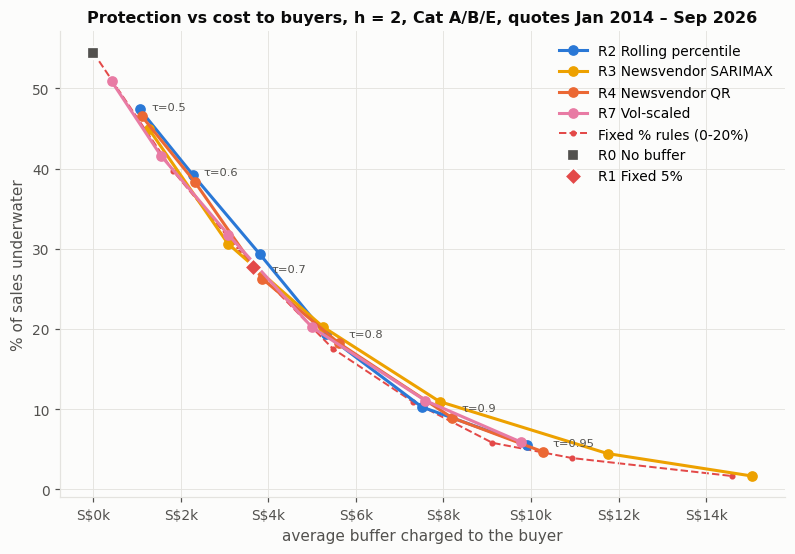

In [6]:
def fixed_curve(d, pcts=(0, 2.5, 5, 7.5, 10, 12.5, 15, 20)):
    base = d[d.rule == "R0 No buffer"]
    return pd.DataFrame([{"pct": p, **score(base.assign(buffer=base.premium_now * p / 100))} for p in pcts])

def frontier(ax, d, title, rules=("R2 Rolling percentile", "R3 Newsvendor SARIMAX", "R4 Newsvendor QR", "R7 Vol-scaled"), label_tau=True):
    s = score_table(d, by=("rule", "tau"))
    for rule in rules:
        g = s[s.rule == rule].sort_values("tau")
        ax.plot(g.avg_buffer, g.underwater_pct, marker="o", ms=6, color=RULE_COLORS[rule], label=rule)
        if label_tau and rule == "R4 Newsvendor QR":
            for r in g.itertuples():
                ax.annotate(f"τ={r.tau}", (r.avg_buffer, r.underwater_pct), textcoords="offset points",
                            xytext=(6, 4), fontsize=7.5, color="#52514e")
    fx = fixed_curve(d)
    ax.plot(fx.avg_buffer, fx.underwater_pct, ls="--", lw=1.3, color=RULE_COLORS["R1 Fixed 5%"], marker=".", ms=6,
            label="Fixed % rules (0-20%)", zorder=1)
    for rule, mk in [("R0 No buffer", "s"), ("R1 Fixed 5%", "D")]:
        g = s[s.rule == rule]
        ax.scatter(g.avg_buffer, g.underwater_pct, marker=mk, s=70, color=RULE_COLORS[rule], zorder=5,
                   edgecolor="#fcfcfb", lw=1.5, label=rule)
    ax.xaxis.set_major_formatter(FuncFormatter(sgd)); ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("average buffer charged to the buyer"); ax.set_ylabel("% of sales underwater")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
frontier(ax, bt, "Protection vs cost to buyers, h = 2, Cat A/B/E, quotes Jan 2014 – Sep 2026")
ax.legend(loc="upper right"); save(fig, "07_frontier.png"); plt.show()

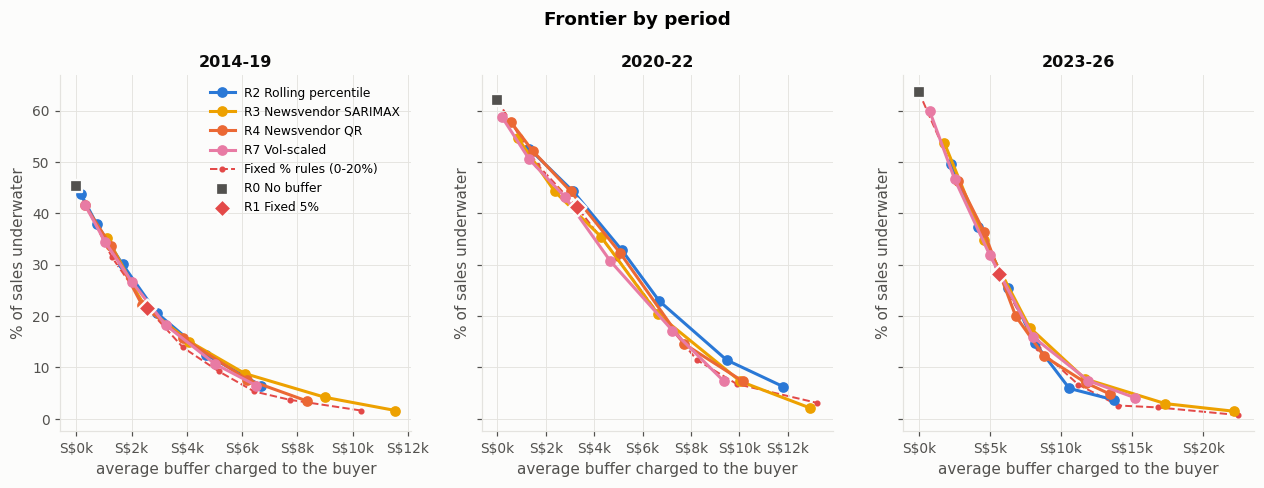

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (p, g) in zip(axes, bt.groupby("period")):
    frontier(ax, g, p, label_tau=False)
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Frontier by period", fontweight="bold", y=1.02); save(fig, "07_frontier_by_period.png"); plt.show()

## Comparable protection at a lower cost?

For each model rule, interpolate its frontier at the fixed-5% rule's underwater rate: what buffer gives the same protection?

In [8]:
def buffer_at(rule, target_uw, d=bt):
    s = score_table(d[d.rule == rule], by=("rule", "tau")).sort_values("underwater_pct")
    return np.interp(target_uw, s.underwater_pct, s.avg_buffer)
rows = []
for p, d in [("2014-26", bt)] + list(bt.groupby("period")):
    r1 = score(d[d.rule == "R1 Fixed 5%"])
    row = {"period": p, "R1 underwater %": r1["underwater_pct"], "R1 avg buffer": r1["avg_buffer"]}
    for rule in ["R2 Rolling percentile", "R3 Newsvendor SARIMAX", "R4 Newsvendor QR", "R6 Combo M1+M3", "R7 Vol-scaled", "R8 M1 adaptive"]:
        row[f"{rule.split()[0]} buffer at same protection"] = buffer_at(rule, r1["underwater_pct"], d)
    rows.append(row)
same = pd.DataFrame(rows); same.to_csv(PROC / "same_protection_cost.csv", index=False)
same.round(0)

,period,R1 underwater %,R1 avg buffer,R2 buffer at same protection,R3 buffer at same protection,R4 buffer at same protection,R6 buffer at same protection,R7 buffer at same protection,R8 buffer at same protection
0,2014-26,28.000,"3,647.000","4,045.000","3,686.000","3,673.000","3,872.000","3,751.000","4,164.000"
1,2014-19,22.000,"2,575.000","2,792.000","2,559.000","2,535.000","2,846.000","2,759.000","2,884.000"
2,2020-22,41.000,"3,299.000","3,679.000","3,043.000","3,564.000","3,452.000","3,097.000","3,499.000"
3,2023-26,28.000,"5,611.000","5,817.000","5,846.000","5,713.000","5,718.000","5,709.000","5,960.000"


## Newsvendor cost per car: model rule at τ* = k/(1+k) vs the fixed 5%, with block-bootstrap CIs

Cost per car = shortfall + excess ÷ k (c_u = 1, c_o = 1/k). Confidence intervals: moving-block bootstrap over rounds (blocks of 8 consecutive rounds, 1,000 resamples) of the per-round cost difference.

In [9]:
best_rule = {"M1": "R2 Rolling percentile", "M2": "R3 Newsvendor SARIMAX", "M3": "R4 Newsvendor QR",
             "M4": "R5 GBM (stretch)", "M5": "R6 Combo M1+M3", "M6": "R7 Vol-scaled", "M7": "R8 M1 adaptive"}[best]
print("buffer model:", best, "->", best_rule)
rows = []
for rule in dict.fromkeys([best_rule, "R2 Rolling percentile", "R7 Vol-scaled", "R8 M1 adaptive", "R4 Newsvendor QR"]):
    for k in K_COST:
        tau = min(TAUS, key=lambda x: abs(x - k / (1 + k)))
        ci = block_bootstrap_diff(bt, rule, tau, "R1 Fixed 5%", None, k)
        a = score(bt[(bt.rule == rule) & (bt.tau == tau)])[f"cost_k{k}"]
        b = score(bt[bt.rule == "R1 Fixed 5%"])[f"cost_k{k}"]
        rows.append({"rule": rule, "k": k, "tau": tau, "cost_rule": a, "cost_R1": b, **ci})
boot = pd.DataFrame(rows); boot.to_csv(PROC / "bootstrap_vs_R1.csv", index=False)
boot[["rule", "k", "tau", "cost_rule", "cost_R1", "mean_diff", "ci_low", "ci_high", "share_boot_below_0"]].round(1)

buffer model: M6 -> R7 Vol-scaled


,rule,k,tau,cost_rule,cost_R1,mean_diff,ci_low,ci_high,share_boot_below_0
0,R7 Vol-scaled,1.000,0.500,"4,375.600","5,091.700",-716.100,-998.100,-339.200,1.000
1,R7 Vol-scaled,2.300,0.700,"2,755.300","2,723.500",31.800,-34.000,113.400,0.100
2,R7 Vol-scaled,4.000,0.800,"1,971.000","1,949.300",21.700,-56.600,97.500,0.300
3,R7 Vol-scaled,9.000,0.900,"1,138.500","1,367.400",-228.900,-402.300,-95.100,1.000
4,R2 Rolling percentile,1.000,0.500,"4,398.000","5,091.700",-693.600,-934.700,-374.200,1.000
5,R2 Rolling percentile,2.300,0.700,"2,755.800","2,723.500",32.300,-55.100,126.900,0.200
6,R2 Rolling percentile,4.000,0.800,"1,911.400","1,949.300",-37.900,-156.400,51.700,0.800
7,R2 Rolling percentile,9.000,0.900,"1,124.900","1,367.400",-242.500,-410.600,-120.000,1.000
8,R8 M1 adaptive,1.000,0.500,"4,451.400","5,091.700",-640.300,-879.200,-326.200,1.000
9,R8 M1 adaptive,2.300,0.700,"2,799.800","2,723.500",76.300,-24.900,190.200,0.100


In [10]:
r0 = score(bt[bt.rule == "R0 No buffer"])
print("No-buffer rule newsvendor cost per car:", {k: round(r0[f'cost_k{k}']) for k in K_COST})
print("R4 vs R0, bootstrap:")
pd.DataFrame([block_bootstrap_diff(bt, "R4 Newsvendor QR", min(TAUS, key=lambda x: abs(x - k/(1+k))), "R0 No buffer", None, k)
              for k in K_COST]).round(1)

No-buffer rule newsvendor cost per car: {1: 4381, 2.3: 3244, 4: 2873, 9: 2594}
R4 vs R0, bootstrap:


,k,mean_diff,ci_low,ci_high,share_boot_below_0,n_rounds
0,1.000,28.400,-137.800,199.800,0.400,298
1,2.300,-439.600,-762.100,-190.200,1.000,298
2,4.000,-888.600,"-1,287.700",-561.700,1.000,298
3,9.000,"-1,444.900","-1,888.300","-1,084.700",1.000,298


## A tougher benchmark: the best fixed-% buffer chosen in hindsight

For each k, find the fixed percentage that would have minimised the newsvendor cost over 2014–2026 (this uses future data, so it flatters the fixed rule), and compare it with the model rules at τ* = k/(1+k), which use only past data.

In [11]:
pcts = np.arange(0, 25.01, 0.5)
base = bt[bt.rule == "R0 No buffer"]
rows = []
for k in K_COST:
    costs = [score(base.assign(buffer=base.premium_now * p / 100))[f"cost_k{k}"] for p in pcts]
    tau = min(TAUS, key=lambda x: abs(x - k / (1 + k)))
    row = {"k": k, "tau*": tau, "best_fixed_pct (hindsight)": pcts[int(np.argmin(costs))], "cost_best_fixed": min(costs),
           "cost_R1_5pct": score(bt[bt.rule == "R1 Fixed 5%"])[f"cost_k{k}"]}
    for rule in ["R2 Rolling percentile", "R4 Newsvendor QR", "R6 Combo M1+M3", "R7 Vol-scaled", "R8 M1 adaptive"]:
        row[f"cost_{rule.split()[0]}"] = score(bt[(bt.rule == rule) & (bt.tau == tau)])[f"cost_k{k}"]
    rows.append(row)
hind = pd.DataFrame(rows); hind.to_csv(PROC / "vs_best_fixed_pct.csv", index=False)
hind.round(1)

,k,tau*,best_fixed_pct (hindsight),cost_best_fixed,cost_R1_5pct,cost_R2,cost_R4,cost_R6,cost_R7,cost_R8
0,1.000,0.500,1.000,"4,347.500","5,091.700","4,398.000","4,409.500","4,381.400","4,375.600","4,451.400"
1,2.300,0.700,4.000,"2,709.700","2,723.500","2,755.800","2,804.800","2,751.300","2,755.300","2,799.800"
2,4.000,0.800,6.500,"1,908.300","1,949.300","1,911.400","1,984.300","1,925.000","1,971.000","1,930.100"
3,9.000,0.900,9.500,"1,095.600","1,367.400","1,124.900","1,148.700","1,120.500","1,138.500","1,139.000"


## Test period only (2020–2026)

The model used for the buffer was chosen on 2014–19, so 2020–26 is clean out-of-sample evidence. The same comparisons against the fixed 5% rule, on test-period quotes only.

In [12]:
bt_test = bt[bt.period.isin(TEST_PERIODS)]
rows = []
for rule in dict.fromkeys([best_rule, "R2 Rolling percentile", "R7 Vol-scaled", "R8 M1 adaptive", "R4 Newsvendor QR"]):
    for k in K_COST:
        tau = min(TAUS, key=lambda x: abs(x - k / (1 + k)))
        ci = block_bootstrap_diff(bt_test, rule, tau, "R1 Fixed 5%", None, k)
        rows.append({"rule": rule, "k": k, "tau": tau,
                     "cost_rule": score(bt_test[(bt_test.rule == rule) & (bt_test.tau == tau)])[f"cost_k{k}"],
                     "cost_R1": score(bt_test[bt_test.rule == "R1 Fixed 5%"])[f"cost_k{k}"], **ci})
boot_test = pd.DataFrame(rows); boot_test.to_csv(PROC / "bootstrap_vs_R1_test.csv", index=False)
display(boot_test[["rule", "k", "tau", "cost_rule", "cost_R1", "mean_diff", "ci_low", "ci_high", "share_boot_below_0"]].round(1))
r1t = score(bt_test[bt_test.rule == "R1 Fixed 5%"])
print(f"Test period: fixed 5% underwater on {r1t['underwater_pct']:.1f}% of sales, average buffer S${r1t['avg_buffer']:,.0f}.")
for rule in dict.fromkeys([best_rule, "R2 Rolling percentile", "R7 Vol-scaled", "R8 M1 adaptive"]):
    print(f"  {rule} needs S${buffer_at(rule, r1t['underwater_pct'], bt_test):,.0f} for the same protection.")

,rule,k,tau,cost_rule,cost_R1,mean_diff,ci_low,ci_high,share_boot_below_0
0,R7 Vol-scaled,1.000,0.500,"5,399.100","5,922.700",-523.600,"-1,006.200",84.500,0.900
1,R7 Vol-scaled,2.300,0.700,"3,391.700","3,277.800",113.900,38.700,239.500,0.000
2,R7 Vol-scaled,4.000,0.800,"2,410.900","2,413.200",-2.200,-141.100,155.500,0.500
3,R7 Vol-scaled,9.000,0.900,"1,379.300","1,763.200",-384.000,-668.800,-137.000,1.000
4,R2 Rolling percentile,1.000,0.500,"5,467.500","5,922.700",-455.200,-807.400,-21.700,1.000
5,R2 Rolling percentile,2.300,0.700,"3,375.000","3,277.800",97.200,-24.300,243.800,0.100
6,R2 Rolling percentile,4.000,0.800,"2,285.800","2,413.200",-127.400,-340.600,46.000,0.900
7,R2 Rolling percentile,9.000,0.900,"1,332.200","1,763.200",-431.000,-699.800,-228.000,1.000
8,R8 M1 adaptive,1.000,0.500,"5,566.500","5,922.700",-356.300,-668.100,40.400,1.000
9,R8 M1 adaptive,2.300,0.700,"3,444.500","3,277.800",166.700,17.500,343.000,0.000


Test period: fixed 5% underwater on 33.5% of sales, average buffer S$4,650.
  R7 Vol-scaled needs S$4,615 for the same protection.
  R2 Rolling percentile needs S$4,927 for the same protection.
  R8 M1 adaptive needs S$5,016 for the same protection.


## Big-jump episodes: Cat B, late 2023 – early 2024. Did each rule see them coming?

In [13]:
ep = bt[(bt.category == "B") & bt.month.between("2023-09", "2024-01") & (bt.tau.isna() | (bt.tau == 0.9))]
tab = ep.pivot_table(index=["month", "bidding_no", "premium_now", "actual_sgd"], columns="rule", values="buffer").round(0)
tab

rule                                        R0 No buffer  R1 Fixed 5%  R2 Rolling percentile  R3 Newsvendor SARIMAX  R4 Newsvendor QR  R5 GBM (stretch)  R6 Combo M1+M3  \
month   bidding_no premium_now actual_sgd                                                                                                                                 
2023-09 1          134889      11,113.000          0.000    6,744.000             16,226.000             21,629.000        13,925.000        14,699.000      15,076.000   
        2          140889      9,112.000           0.000    7,044.000             15,796.000             22,610.000        14,679.000        16,959.000      15,237.000   
2023-10 1          146002      -36,001.000         0.000    7,300.000             15,514.000             20,864.000        16,245.000        22,384.000      15,880.000   
        2          150001      -14,665.000         0.000    7,500.000             15,461.000             19,805.000        16,860.000        19,226.000      16,160.000   
2023-11 1          110001      20,099.000          0.000    5,500.000             11,126.000             15,164.000        16,804.000        21,256.000      13,965.000   
        2          135336      -25,335.000         0.000    6,767.000             13,688.000             24,177.000        20,914.000        14,354.000      17,301.000   
2023-12 1          130100      -45,090.000         0.000    6,505.000             13,410.000             19,824.000        19,422.000        18,833.000      16,416.000   
        2          110001      1,999.000           0.000    5,500.000             11,338.000             16,027.000        20,094.000        18,956.000      15,716.000   
2024-01 1          85010       17,328.000          0.000    4,250.000              8,762.000             11,526.000        16,923.000        17,328.000      12,843.000   
        2          112000      -15,000.000         0.000    5,600.000             11,544.000             21,906.000        20,213.000        15,117.000      15,879.000   

rule                                        R7 Vol-scaled  R8 M1 adaptive  
month   bidding_no premium_now actual_sgd                                  
2023-09 1          134889      11,113.000      12,357.000      17,137.000  
        2          140889      9,112.000       12,837.000      16,712.000  
2023-10 1          146002      -36,001.000     13,192.000      16,427.000  
        2          150001      -14,665.000     13,392.000      16,361.000  
2023-11 1          110001      20,099.000      16,422.000      11,758.000  
        2          135336      -25,335.000     24,124.000      14,433.000  
2023-12 1          130100      -45,090.000     22,800.000      14,418.000  
        2          110001      1,999.000       20,184.000      12,163.000  
2024-01 1          85010       17,328.000      17,447.000       9,379.000  
        2          112000      -15,000.000     27,446.000      12,328.000

In [14]:
big = bt[(bt.rule == "R0 No buffer")].nlargest(8, "actual_sgd")[["category", "month", "bidding_no", "premium_now", "actual_sgd"]]
cov = []
for r in big.itertuples():
    d = bt[(bt.category == r.category) & (bt.month == r.month) & (bt.bidding_no == r.bidding_no) & (bt.tau.isna() | (bt.tau == 0.9))]
    cov.append({"category": r.category, "month": r.month, "round": r.bidding_no, "rise": r.actual_sgd,
                **{k.split()[0]: v for k, v in d.set_index("rule").buffer.items()}})
print("The 8 largest 2-round rises and the buffer each rule charged (model rules at τ = 0.9):")
pd.DataFrame(cov).round(0)

The 8 largest 2-round rises and the buffer each rule charged (model rules at τ = 0.9):


,category,month,round,rise,R0,R1,R2,R3,R4,R5,R6,R7,R8
0,A,2025-09,1,"20,216.000",0.000,"5,394.000","7,911.000","14,903.000","7,781.000","9,549.000","7,846.000","8,958.000","7,614.000"
1,B,2023-11,1,"20,099.000",0.000,"5,500.000","11,126.000","15,164.000","16,804.000","21,256.000","13,965.000","16,422.000","11,758.000"
2,B,2022-10,1,"19,532.000",0.000,"4,793.000","15,014.000","14,586.000","11,659.000","12,893.000","13,336.000","10,156.000","15,948.000"
3,E,2024-12,1,"18,999.000",0.000,"5,200.000","9,112.000","15,143.000","9,435.000","12,811.000","9,274.000","8,722.000","8,774.000"
4,B,2024-12,1,"18,491.000",0.000,"5,150.000","9,345.000","14,333.000","11,597.000","15,017.000","10,471.000","14,283.000","9,783.000"
5,B,2024-01,1,"17,328.000",0.000,"4,250.000","8,762.000","11,526.000","16,923.000","17,328.000","12,843.000","17,447.000","9,379.000"
6,E,2025-08,2,"15,501.000",0.000,"6,250.000","10,657.000","21,330.000","8,579.000","9,880.000","9,618.000","8,857.000","10,032.000"
7,E,2021-10,1,"15,244.000",0.000,"3,638.000","8,803.000","14,754.000","7,499.000","6,115.000","8,151.000","7,599.000","9,585.000"


## Sensitivity: horizon h = 1, 3, 4 and the refund case

In [15]:
rows = []
for h in HORIZONS:
    b = rule_buffers(fc, h, extra={"R7 Vol-scaled": "M6", "R8 M1 adaptive": "M7"})
    s = score_table(b[b.tau.isna() | (b.tau == 0.8)], by=("rule",))
    rows.append(s.assign(h=h))
sens = pd.concat(rows); sens.to_csv(PROC / "backtest_sensitivity_h.csv", index=False)
print("Share underwater (%), model rules at tau = 0.8:")
display(sens.pivot(index="rule", columns="h", values="underwater_pct").round(1))
print("Average buffer (S$):")
display(sens.pivot(index="rule", columns="h", values="avg_buffer").round(0))

Share underwater (%), model rules at tau = 0.8:


h,1,2,3,4
rule,,,,
R0 No buffer,54.700,54.500,53.200,55.000
R1 Fixed 5%,16.000,27.700,32.500,35.300
R2 Rolling percentile,19.900,19.400,19.300,19.000
R3 Newsvendor SARIMAX,10.200,11.000,10.800,9.300
R4 Newsvendor QR,19.400,18.200,17.800,19.200
R7 Vol-scaled,20.800,20.200,20.500,18.800
R8 M1 adaptive,20.000,19.600,19.600,19.600


Average buffer (S$):


h,1,2,3,4
rule,,,,
R0 No buffer,0.000,0.000,0.000,0.000
R1 Fixed 5%,"3,650.000","3,647.000","3,644.000","3,640.000"
R2 Rolling percentile,"3,118.000","5,306.000","6,820.000","8,138.000"
R3 Newsvendor SARIMAX,"5,024.000","7,911.000","10,273.000","12,390.000"
R4 Newsvendor QR,"3,388.000","5,612.000","7,227.000","7,641.000"
R7 Vol-scaled,"3,068.000","4,992.000","6,235.000","7,451.000"
R8 M1 adaptive,"3,269.000","5,314.000","6,907.000","8,158.000"


In [16]:
ref = overall[overall.tau.isna() | (overall.tau == 0.8)][["rule", "avg_buffer", "avg_buyer_cost_refund", "avg_loss_per_car"]]
ref["buyer_saving_if_refund"] = ref.avg_buffer - ref.avg_buyer_cost_refund
print("Refund case: buyer gets back any unused buffer (dealer's shortfall unchanged), h = 2, tau = 0.8")
ref.round(0)

Refund case: buyer gets back any unused buffer (dealer's shortfall unchanged), h = 2, tau = 0.8


,rule,avg_buffer,avg_buyer_cost_refund,avg_loss_per_car,buyer_saving_if_refund
0,R0 No buffer,0.000,0.000,"2,370.000",0.000
1,R1 Fixed 5%,"3,647.000","1,468.000",902.000,"2,179.000"
5,R2 Rolling percentile,"5,306.000","1,830.000",540.000,"3,476.000"
11,R3 Newsvendor SARIMAX,"7,911.000","2,062.000",308.000,"5,849.000"
17,R4 Newsvendor QR,"5,612.000","1,833.000",537.000,"3,779.000"
23,R5 GBM (stretch),"5,100.000","1,764.000",606.000,"3,337.000"
29,R6 Combo M1+M3,"5,459.000","1,850.000",520.000,"3,609.000"
35,R7 Vol-scaled,"4,992.000","1,720.000",650.000,"3,272.000"
41,R8 M1 adaptive,"5,314.000","1,817.000",553.000,"3,497.000"
